# **Base de Dados:**
[Site:LondonDataStore](https://data.london.gov.uk/dataset/smartmeter-energy-consumption-data-in-london-households-vqm0d)

**SmartMeter Energy Consumption Data in London Households**



*   Leitura de consumo de energia para uma amostra de 5567 residências de Londres (projeto Low Carbon London).
*   168 arquivos .csv



# Inicialização


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import json
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from google.colab import drive
import gc
import pyarrow as pa
import pyarrow.parquet as pq

####**Histórico dos Códigos utilizados para pré-tratamento dos Dados**

- Os 168 arquivos foram divididos em duas pastas do drive para pré-compilação


In [ ]:
drive.mount('/content/drive')

#Dividindo arquivos em duas partes devido a quantidade de arquivos:
project_directory1 = Path("/content/drive/MyDrive/IC/Data/Data_Londres/Small_LCL_Data/part1")
project_directory2 = Path("/content/drive/MyDrive/IC/Data/Data_Londres/Small_LCL_Data/part2")

# Check if the project directory exists
if not project_directory1.exists():
    print(f"Error: Project directory 1 not found - {project_directory1}")
else:
    print(f"Project directory 1 found: {project_directory1}")

if not project_directory2.exists():
    print(f"Error: Project directory 2 not found - {project_directory2}")
else:
    print(f"Project directory 2 found: {project_directory2}")

# Input folder
directory1 = project_directory1
directory2 = project_directory2

# Output folder
output_directory1 = project_directory1 / "output_data_part1"
output_directory1.mkdir(parents=True, exist_ok=True)

output_directory2 = project_directory2 / "output_data_part2"
output_directory2.mkdir(parents=True, exist_ok=True)

#Creating a list of all files in the folder
files_list1 = list(directory1.glob("*.csv"))
print(f"\nfiles found parte 1: {len(files_list1)}")

files_list2 = list(directory2.glob("*.csv"))
print(f"\nfiles found parte 2: {len(files_list2)}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory 1 found: /content/drive/MyDrive/IC/Data/Data_Londres/Small_LCL_Data/part1
Project directory 2 found: /content/drive/MyDrive/IC/Data/Data_Londres/Small_LCL_Data/part2

files found parte 1: 0

files found parte 2: 2


**Pré-Compilação dos Dados**
*   Ajuste do tipo de dado trabalhado, remoção das suplicatas e interpolação dos dados.
*   Definição aleatória do FP de cada residência dentro do intervalo de [0.85 , 0,95]
*   Cálculo da Potência Reativa de cada residência

In [ ]:
# ============================================================
# DATA LOADING AND PREPOCESSING - Part 1
# ============================================================

#------------Function to analyze and adjust files-------------#
def analyze_data(df_input):
    df = df_input.copy()

    ## Remove extra whitespace from column names:
    df.columns = df.columns.str.strip()

    ## Data type adjustment:
    df["DateTime"] = pd.to_datetime(df["DateTime"])
    df["KWH/hh (per half hour)"] = pd.to_numeric(
    df["KWH/hh (per half hour)"], errors="coerce")

    ## Removing duplicate lines:
    df = df.drop_duplicates()

    ## Creating a DataFrame with interpolation via .apply() for each group (LCLid):
    df_interp = (df.set_index("DateTime").groupby("LCLid")["KWH/hh (per half hour)"].apply(lambda x: x.resample("15min").interpolate(method="linear")) / 2).reset_index()

    ## Creating a column for power in kW (15-min):
    df_interp["power_kW"] = df_interp["KWH/hh (per half hour)"] * 4

    ## Defining the data range to be used (2012–2014):
    df_range = df_interp[
        (df_interp["DateTime"].dt.year >= 2012)
        & (df_interp["DateTime"].dt.year <= 2014)
    ].copy()

    # ==============================================
    # POWER FACTOR AND REACTIVE POWER CALCULATION
    # ==============================================
    ## Identifying the residences:
    residences = df_range["LCLid"].unique()

    ## Generating FP values for each residence:
    fp_resid = {
	      lcl: np.round(rng_fp1.uniform(0.85, 0.95), 2)
	      for lcl in residences}

	  ## Creating a column for FP:
    df_range["power_factor"] = df_range["LCLid"].map(fp_resid)

    ## Creating a column for reactive power calculation:
    fp = df_range["power_factor"]
    df_range["power_kVar"] = (df_range["power_kW"] * (np.sqrt(1 - fp**2) / fp))

    # ==============================================
    #  DATA DIAGNOSTICS AND PROCESSED FILES
    # ==============================================

    ## Selecting residence information:
    file_summary1 = df_range.groupby("LCLid").agg(
        start_date=("DateTime", "min"),
        end_date=("DateTime", "max"),
        values_count=("KWH/hh (per half hour)", "count"),
        errors=("KWH/hh (per half hour)", lambda x: x.isna().sum()),
        error_rate=(
            "KWH/hh (per half hour)",
            lambda x: x.isna().mean() * 100,),
        mean_kW=("power_kW", "mean"),
        max_kW=("power_kW", "max"),
        min_kW=("power_kW", "min"),
        std_kW=("power_kW", "std"),
        mean_kVar=("power_kVar", "mean"),
        max_kVar=("power_kVar", "max"),
        power_factor=("power_factor", "first")
    )

    return df_range, file_summary1

all_processed_data1 = []

In [ ]:
# ---------- Loop to open each file and make the changes ----------

import gc

# List to store diagnostic information
diagnostics1 = []


for i, file in enumerate(files_list1, start=1):

    print(f"Processing file {i}/{len(files_list1)}: {file.name}")

    # Read CSV file
    df_temp = pd.read_csv(file)

    # Analyze and preprocess data
    df_processed, diag = analyze_data(df_temp)

    # Store diagnostics
    diagnostics1.append(diag)

    #Salvando arquivos
    output_filename = output_directory1 / f"processed_{file.name}"
    df_processed.to_csv(output_filename, index=False)

    print(f"Saved: {output_filename.name}")

    # Remove DataFrames from memory
    del df_temp
    del df_processed
    del diag

    # Free unused memory
    gc.collect()


# Generate CSV file with residence diagnostics
all_diagnostics1 = pd.concat(diagnostics1).reset_index()

# Save the diagnostics file
all_diagnostics1.to_csv(output_directory1 / "diagnostico_casas_2013_2014.csv",index=False)

print("Processing completed part 1")

In [ ]:
# ============================================================
# DATA LOADING AND PREPOCESSING - Part 2 (seed diferente)
# ============================================================

#------------Function to analyze and adjust files-------------#
def analyze_data(df_input):
    df = df_input.copy()

    ## Remove extra whitespace from column names:
    df.columns = df.columns.str.strip()

    ## Data type adjustment:
    df["DateTime"] = pd.to_datetime(df["DateTime"])
    df["KWH/hh (per half hour)"] = pd.to_numeric(
    df["KWH/hh (per half hour)"], errors="coerce"
    )

    ## Removing duplicate lines:
    df = df.drop_duplicates()

    ## Creating a DataFrame with interpolation via .apply() for each group (LCLid):
    df_interp = (
        df.set_index("DateTime")
        .groupby("LCLid")["KWH/hh (per half hour)"]
        .apply(lambda x: x.resample("15min").interpolate(method="linear"))
        / 2
    ).reset_index()

    ## Creating a column for power in kW (15-min):
    df_interp["power_kW"] = df_interp["KWH/hh (per half hour)"] * 4

    ## Defining the data range to be used (2012–2014):
    df_range = df_interp[
        (df_interp["DateTime"].dt.year >= 2012)
        & (df_interp["DateTime"].dt.year <= 2014)
    ].copy()

    # ==============================================
    # POWER FACTOR AND REACTIVE POWER CALCULATION
    # ==============================================
    ## Identifying the residences:
    residences = df_range["LCLid"].unique()

    ## Generating FP values for each residence:
    fp_resid = {
	      lcl: np.round(rng_fp2.uniform(0.85, 0.95), 2)
	      for lcl in residences}

	  ## Creating a column for FP:
    df_range["power_factor"] = df_range["LCLid"].map(fp_resid)

    ## Creating a column for reactive power calculation:
    fp = df_range["power_factor"]
    df_range["power_kVar"] = (df_range["power_kW"] * (np.sqrt(1 - fp**2) / fp))

    # ==============================================
    #  DATA DIAGNOSTICS AND PROCESSED FILES
    # ==============================================

    ## Selecting residence information:
    file_summary2 = df_range.groupby("LCLid").agg(
        start_date=("DateTime", "min"),
        end_date=("DateTime", "max"),
        values_count=("KWH/hh (per half hour)", "count"),
        errors=("KWH/hh (per half hour)", lambda x: x.isna().sum()),
        error_rate=(
            "KWH/hh (per half hour)",
            lambda x: x.isna().mean() * 100,),
        mean_kW=("power_kW", "mean"),
        max_kW=("power_kW", "max"),
        min_kW=("power_kW", "min"),
        std_kW=("power_kW", "std"),
        mean_kVar=("power_kVar", "mean"),
        max_kVar=("power_kVar", "max"),
        power_factor=("power_factor", "first")
    )

    return df_range, file_summary2

all_processed_data2 = []

In [ ]:
# ---------- Loop to open each file and make the changes ----------

import gc

# List to store diagnostic information
diagnostics2 = []

# Process Part 2
for i, file in enumerate(files_list2, start=1):

    print(f"Processing file {i}/{len(files_list2)}: {file.name}")

    # Read CSV file
    df_temp = pd.read_csv(file)

    # Analyze and preprocess data
    df_processed, diag = analyze_data(df_temp)

    # Store diagnostics
    diagnostics2.append(diag)

    #Salvando arquivos
    output_filename = output_directory2 / f"processed_{file.name}"
    df_processed.to_csv(output_filename, index=False)

    print(f"Saved: {output_filename.name}")

    # Remove DataFrames from memory
    del df_temp
    del df_processed
    del diag

    # Free unused memory
    gc.collect()


# Generate CSV file with residence diagnostics
all_diagnostics2 = pd.concat(diagnostics2).reset_index()

# Save the diagnostics file
all_diagnostics2.to_csv(output_directory2 / "diagnostico_casas_2013_2014.csv",index=False)

print("Processing completed - Part 2")

**Combinação dos Dados: Parte 1 + Parte 2**

In [ ]:
all_diagnostics1 = pd.read_csv(output_directory1 / "diagnostico_casas_2013_2014.csv")
all_diagnostics2 = pd.read_csv(output_directory2 / "diagnostico_casas_2013_2014.csv")
all_diagnostics = pd.concat([all_diagnostics1, all_diagnostics2],ignore_index=True)
print(all_diagnostics)

**Criação do arquivo Parquet**

In [ ]:
processed_files1 = sorted(output_directory1.glob("processed_*.csv"))
processed_files2 = sorted(output_directory2.glob("processed_*.csv"))
processed_files = processed_files1 + processed_files2

print(f"Processed files found: {len(processed_files)}")

# ------------------------------------------------------------
# Output path
# ------------------------------------------------------------

parquet_output_directory = Path("/content/drive/MyDrive/IC/Data/Data_Londres/Small_LCL_Data")

parquet_output_directory.mkdir(parents=True,exist_ok=True)
parquet_file = (parquet_output_directory/ "smart_meter_data_processed.parquet")

# ------------------------------------------------------------
# Create Parquet file incrementally
# ------------------------------------------------------------

writer = None

for i, file in enumerate(processed_files, start=1):

    print(f"Processing file {i}/{len(processed_files)}: "f"{file.name}")

    # Read one CSV at a time
    df = pd.read_csv(file)

    # Convert DateTime
    df["DateTime"] = pd.to_datetime(df["DateTime"])

    # Convert pandas DataFrame to PyArrow table
    table = pa.Table.from_pandas(df,preserve_index=False)

    # Create the Parquet writer using the first file
    if writer is None:

        writer = pq.ParquetWriter(parquet_file,table.schema,compression="snappy")

    # Add the current file to the Parquet dataset
    writer.write_table(table)

    # Release memory
    del df
    del table

    gc.collect()

# Close the Parquet writer
if writer is not None:
    writer.close()

print("\nParquet file created successfully.")
print(f"Saved at: {parquet_file}")

In [ ]:
parquet_file = Path("/content/drive/MyDrive/IC/Data/Data_Londres/Small_LCL_Data/smart_meter_data_processed.parquet")

parquet_info = pq.ParquetFile(parquet_file)

print(parquet_info.schema.names)

#### **Montagem do Google Drive**

In [ ]:
drive.mount('/content/drive')

directory = Path("/content/drive/MyDrive/IC-2026/Data_London")
parquet_file = Path("/content/drive/MyDrive/IC-2026/Data_London/smart_meter_data_processed.parquet")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Leitura do arquivo Parquet
parquet_info = pq.ParquetFile(parquet_file)
print(parquet_info.schema.names)

['LCLid', 'DateTime', 'KWH/hh (per half hour)', 'power_kW', 'power_factor', 'power_kVar']


# **Análise Estatistíca das Residências**

In [ ]:
# Criação de variável com todas as residências
table = parquet_info.read(columns=["LCLid"])
residences = table["LCLid"].unique()
print(f"Number of residences: {len(residences)}")

Number of residences: 5566


In [ ]:
def statistics_data(data, output_directory):
  statistics = []

  for residence in data:
    print(f"Processing residence: {residence}")

    df_residence = pd.read_parquet(
        parquet_file,
        columns=["LCLid", "DateTime", "power_kW", "power_kVar", "power_factor"],
        filters=[("LCLid", "==", residence)])

    statistics.append({
         "LCLid": residence,
         "start_date": df_residence["DateTime"].min(),
         "end_date": df_residence["DateTime"].max(),
         "values_count": len(df_residence),
         "mean_kW": df_residence["power_kW"].mean(),
         "max_kW": df_residence["power_kW"].max(),
         "min_kW": df_residence["power_kW"].min(),
         "mean_kVar": df_residence["power_kVar"].mean(),
         "max_kVar": df_residence["power_kVar"].max(),
         "min_kVar": df_residence["power_kVar"].min(),
         "power_factor": df_residence["power_factor"].mean(),
     })
    del df_residence

  statistics = pd.DataFrame(statistics)
  statistics.to_csv(output_directory, index=False)

  return statistics

In [ ]:
resid_statistics = statistics_data(residences, directory / "residences_statistics.csv")

resid_statistics.head()

A saída de streaming foi truncada nas últimas 5000 linhas.
Processing residence: MAC000947
Processing residence: MAC000948
Processing residence: MAC000949
Processing residence: MAC000950
Processing residence: MAC000951
Processing residence: MAC000952
Processing residence: MAC000953
Processing residence: MAC000954
Processing residence: MAC000955
Processing residence: MAC000956
Processing residence: MAC000957
Processing residence: MAC000958
Processing residence: MAC000959
Processing residence: MAC000960
Processing residence: MAC000962
Processing residence: MAC000963
Processing residence: MAC000964
Processing residence: MAC000966
Processing residence: MAC000967
Processing residence: MAC000968
Processing residence: MAC000969
Processing residence: MAC000970
Processing residence: MAC000971
Processing residence: MAC000972
Processing residence: MAC000973
Processing residence: MAC000974
Processing residence: MAC000975
Processing residence: MAC000977
Processing residence: MAC000978
Processing re

,LCLid,start_date,end_date,values_count,mean_kW,max_kW,min_kW,mean_kVar,max_kVar,min_kVar,power_factor
0,MAC000002,2012-10-12 00:30:00,2014-02-28,48383,0.504921,5.988,0.000,0.215095,2.550877,0.000000,0.92
1,MAC000003,2012-02-20 13:00:00,2014-02-28,70893,0.794517,7.842,0.014,0.261145,2.577541,0.004602,0.95
2,MAC000004,2012-05-08 13:00:00,2014-02-28,63405,0.070651,2.130,0.000,0.038133,1.149652,0.000000,0.88
3,MAC000006,2012-01-30 11:30:00,2014-02-28,72915,0.118976,1.602,0.000,0.060953,0.820729,0.000000,0.89
4,MAC000007,2012-09-24 12:00:00,2014-02-28,50065,0.395752,7.568,0.030,0.191672,3.665350,0.014530,0.90


## *Plot - Análise Temporal*

In [ ]:
def plot_resid_load(parquet_file, residence):

    df_residence = pd.read_parquet(
        parquet_file,
        columns=["LCLid", "DateTime", "power_kW", "power_kVar"],
        filters=[("LCLid", "==", residence)])

    df_residence["DateTime"] = pd.to_datetime(df_residence["DateTime"])

    power_mean = df_residence["power_kW"].mean()
    reactive_mean = df_residence["power_kVar"].mean()

    # Create plots
    fig, axes = plt.subplots(2, 1,figsize=(14, 8),sharex=True)

    axes[0].plot(df_residence["DateTime"],df_residence["power_kW"],label="Load",color="#F8A4C8")
    axes[0].axhline(power_mean,color="#C2185B",linestyle="--",label=f"Mean: {power_mean:.2f} kW")
    axes[0].set_ylabel("Load (kW)")
    axes[0].set_xlabel("Time")
    axes[0].set_title(f"Active Power Load - Residence {residence}")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(df_residence["DateTime"],df_residence["power_kVar"],label="Load",color="#F8A4C8")
    axes[1].axhline(reactive_mean,color="#C2185B",linestyle="--",label=f"Mean: {reactive_mean:.2f} kVar")
    axes[1].set_ylabel("Load (kVar)")
    axes[1].set_xlabel("Time")
    axes[1].set_title(f"Reactive Power Load - Residence {residence}")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    del df_residence

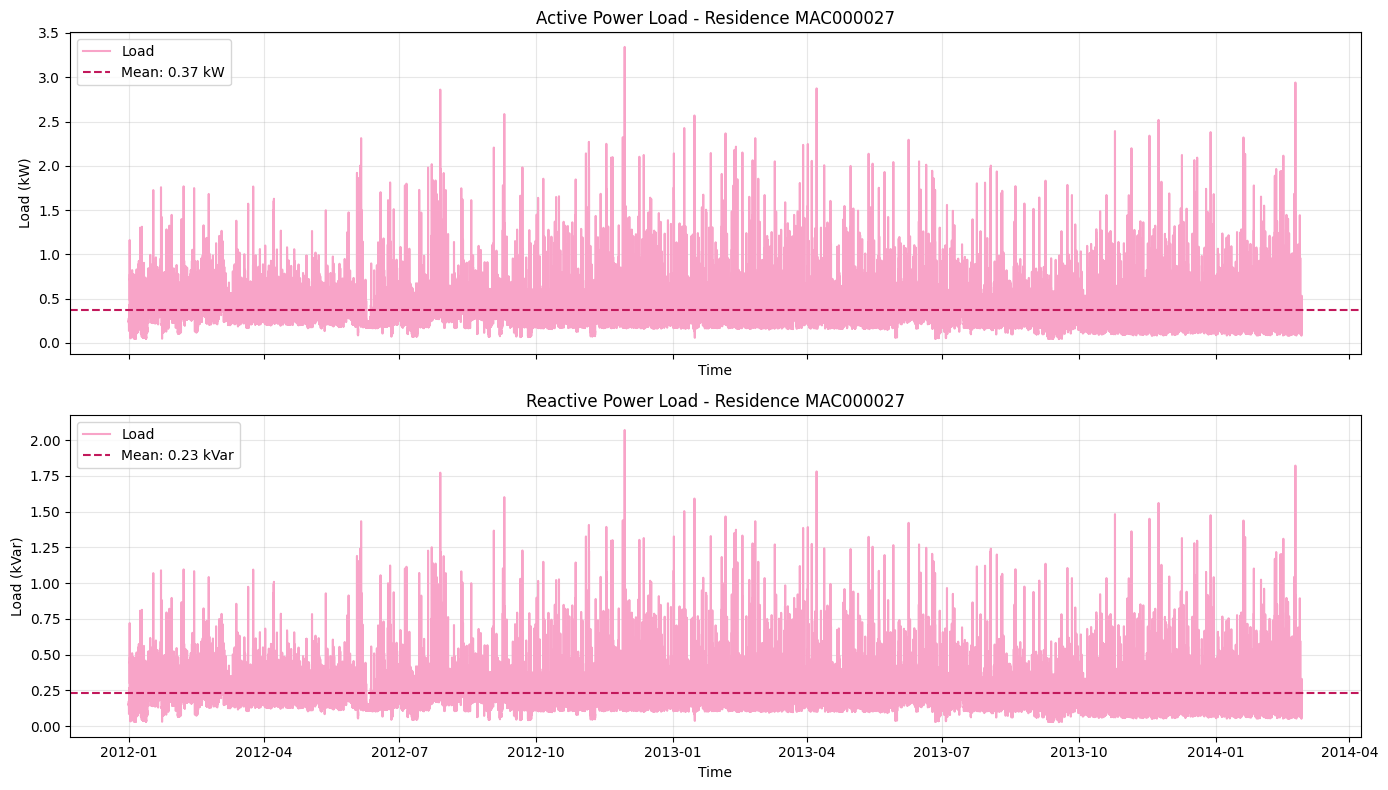

In [ ]:
plot_resid_load(parquet_file, "MAC000027")

#**Normalização dos Dados**

In [ ]:
def normalize_data (parquet_file, residence):

  df_residence = pd.read_parquet(
        parquet_file,
        columns=["LCLid", "DateTime", "power_kW", "power_kVar"],
        filters=[("LCLid", "==", residence)])

  #Potência de Base
  max_kW = df_residence["power_kW"].max()

  df_residence["power_kW_norm"] = (df_residence["power_kW"]/max_kW)
  df_residence["power_kVar_norm"] = (df_residence["power_kVar"]/max_kW)

  df_residence = df_residence[["LCLid", "DateTime", "power_kW_norm", "power_kVar_norm"]]

  return df_residence

In [ ]:
#Limpeza da memória RAM
plt.close("all")

variaveis_para_apagar = [
    "all_diagnostics1",
    "all_diagnostics2",
    "all_diagnostics",
    "df_temp",
    "df_processed",
    "df_residence",
    "df_interp",
    "df_range",
    "table",
    "resid_statistics",
    "statistics",
    "parquet_info"
]

for nome in variaveis_para_apagar:
    if nome in globals():
        del globals()[nome]

gc.collect()
!free -h

               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.9Gi       5.7Gi        10Mi       5.4Gi        10Gi
Swap:             0B          0B          0B


In [ ]:
normalized_parquet = directory / "smart_meter_data_normalized.parquet"

writer = None

residences = pd.read_parquet(parquet_file,columns=["LCLid"])["LCLid"].unique()

try:
    for residence in residences:
        print(f"Processing residence: {residence}")

        df_residence = normalize_data(parquet_file, residence)

        table = pa.Table.from_pandas(df_residence,preserve_index=False)

        if writer is None:
            writer = pq.ParquetWriter(normalized_parquet,table.schema,compression="snappy")

        writer.write_table(table)

        del df_residence
        del table
        gc.collect()

finally:
    if writer is not None:
        writer.close()


A saída de streaming foi truncada nas últimas 5000 linhas.
Processing residence: MAC000947
Processing residence: MAC000948
Processing residence: MAC000949
Processing residence: MAC000950
Processing residence: MAC000951
Processing residence: MAC000952
Processing residence: MAC000953
Processing residence: MAC000954
Processing residence: MAC000955
Processing residence: MAC000956
Processing residence: MAC000957
Processing residence: MAC000958
Processing residence: MAC000959
Processing residence: MAC000960
Processing residence: MAC000962
Processing residence: MAC000963
Processing residence: MAC000964
Processing residence: MAC000966
Processing residence: MAC000967
Processing residence: MAC000968
Processing residence: MAC000969
Processing residence: MAC000970
Processing residence: MAC000971
Processing residence: MAC000972
Processing residence: MAC000973
Processing residence: MAC000974
Processing residence: MAC000975
Processing residence: MAC000977
Processing residence: MAC000978
Processing re

## *Plot - Análise Temporal Dados Normalizados*

In [ ]:
 def plot_resid_norm(parquet_file, residence):

    # Read only the selected residence
    df_residence = pd.read_parquet(parquet_file,columns=[
"LCLid",
            "DateTime",
            "power_kW_norm",
            "power_kVar_norm"
        ],
        filters=[
            ("LCLid", "==", residence)
        ]
    )

    # Convert DateTime to the correct format
    df_residence["DateTime"] = pd.to_datetime(
        df_residence["DateTime"]
    )

    # Calculate mean normalized active and reactive power
    power_norm_mean = df_residence["power_kW_norm"].mean()
    reactive_norm_mean = df_residence["power_kVar_norm"].mean()

    # Create plots
    fig, axes = plt.subplots(2, 1,figsize=(14, 8),sharex=True)

    # Active power
    axes[0].plot(df_residence["DateTime"],df_residence["power_kW_norm"],label="Load",color="#F8A4C8")
    axes[0].axhline(power_norm_mean,color="#C2185B",linestyle="--",label=f"Mean: {power_norm_mean:.2f}")
    axes[0].set_ylabel("Normalized Load")
    axes[0].set_title(f"Normalized Active Power - Residence {residence}")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    # Reactive power
    axes[1].plot(df_residence["DateTime"],df_residence["power_kVar_norm"],label="Load",color="#F8A4C8")
    axes[1].axhline(reactive_norm_mean,color="#C2185B",linestyle="--",label=f"Mean: {reactive_norm_mean:.2f}")
    axes[1].set_ylabel("Normalized Load")
    axes[1].set_xlabel("Time")
    axes[1].set_title(f"Normalized Reactive Power - Residence {residence}")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    del df_residence

**Visualização Temporal do Consumo de potência Ativa e Reativa da residência Normalizado**

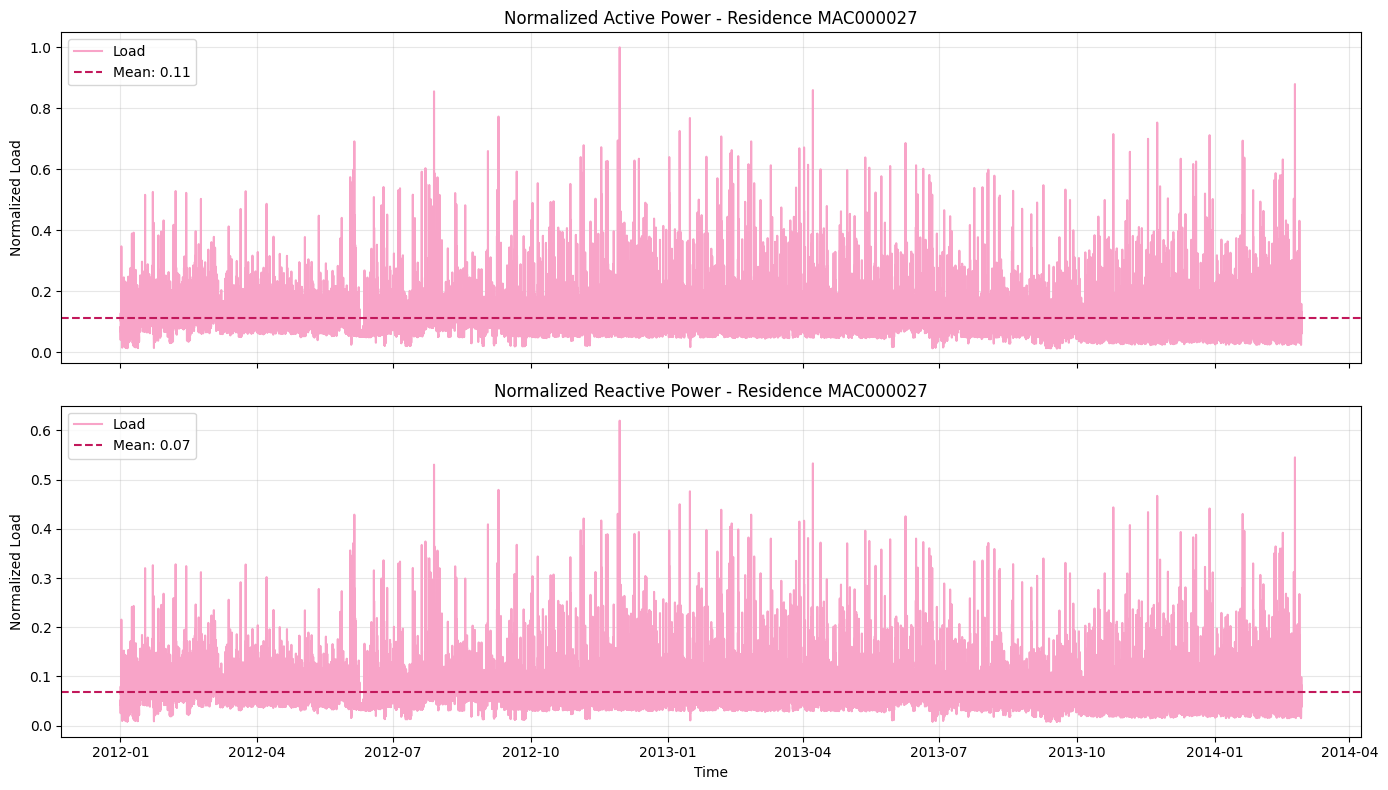

In [ ]:
plot_resid_norm(normalized_parquet, "MAC000027")

## *Plot - Daily Mean Consumption*

In [ ]:
def plot_daily_mean(parquet_file, residence):

    df_residence = pd.read_parquet(
        parquet_file,
        columns=["LCLid","DateTime","power_kW_norm","power_kVar_norm"],
        filters=[("LCLid", "==", residence)])

    df_residence["DateTime"] = pd.to_datetime(df_residence["DateTime"])
    df_residence["Time"] = (df_residence["DateTime"].dt.hour * 60 + df_residence["DateTime"].dt.minute)

    # Média de todos os dias para cada horário
    daily_mean = (df_residence.groupby("Time")[["power_kW_norm", "power_kVar_norm"]].mean().reset_index())

    fig, axes = plt.subplots(2, 1,figsize=(14, 8),sharex=True)

    axes[0].plot(daily_mean["Time"],daily_mean["power_kW_norm"],label="Mean normalized load",color="#F8A4C8")
    axes[0].set_ylabel("Normalized Load")
    axes[0].set_title(f"Average Daily Active Power Profile - Residence {residence}")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(daily_mean["Time"],daily_mean["power_kVar_norm"],label="Mean normalized reactive load",color="#F8A4C8")
    axes[1].set_ylabel("Normalized Load")
    axes[1].set_xlabel("Time")
    axes[1].set_title(f"Average Daily Reactive Power Profile - Residence {residence}")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    del df_residence
    del daily_mean

**Visualização do consumo médio diário de potência Ativa e Reativa da residência**

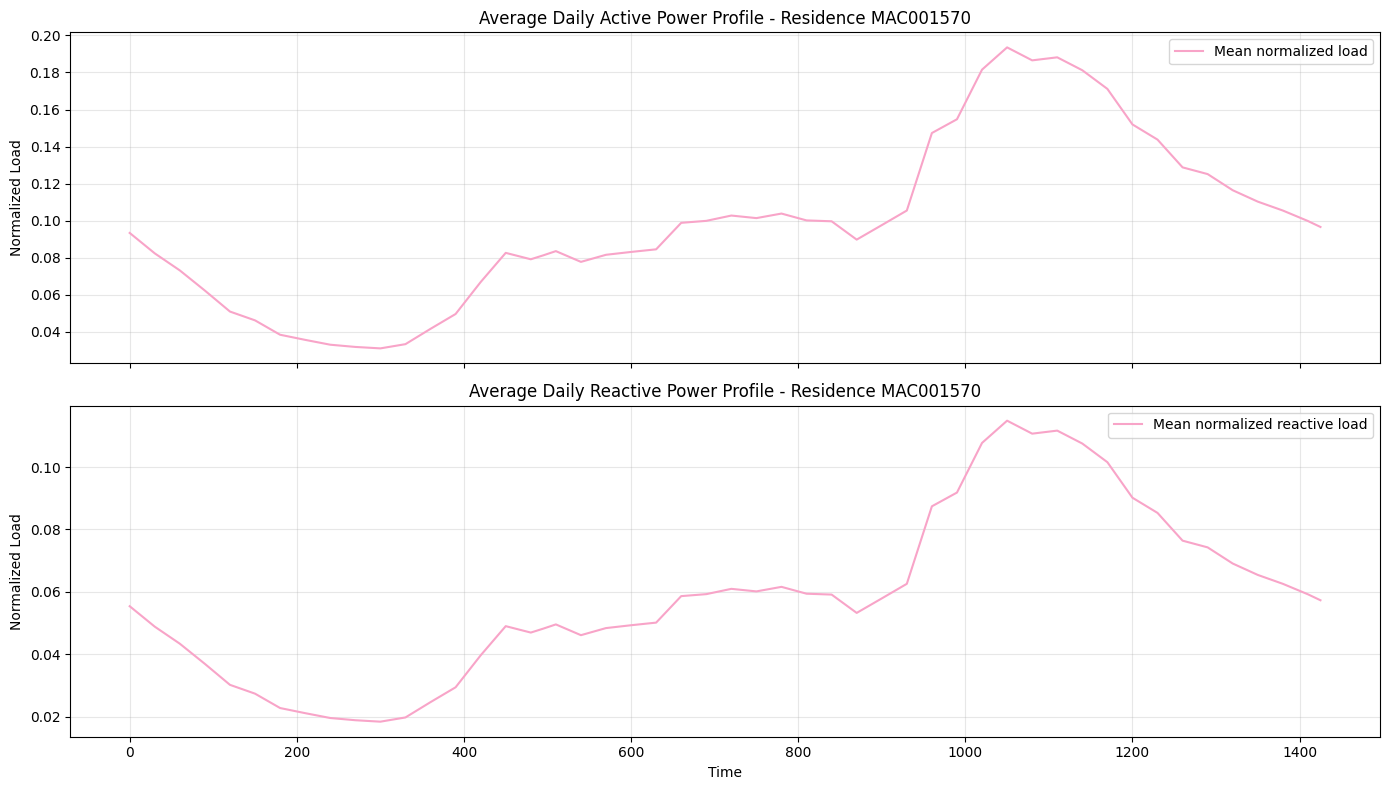

In [ ]:
plot_daily_mean(normalized_parquet, "MAC001570")

# **Análise Gráfica e Criação dos Cenários**
- Definição da quantidade de nós da Rede
- Definição da quantidade de residencias e do tipo de carga decada nó.

## **Seleção dos Perfis**
Seleção das residências baseado em:
- número mínimo de medições: 60000
- Ter perfil ativo majoritariamente durante o dia
- Iniciado as medições antes de 31/03/2012

In [ ]:
def filter_residences(parquet_file, statistics, min_measurements):

  adequate_residences = []

  residences = statistics[
      (statistics["values_count"] >= min_measurements) &
      (statistics["start_date"] <= "2012-03-31")
  ]["LCLid"].unique()

  for residence in residences:
    print(f"Processing residence: {residence}")

    df_residence = pd.read_parquet(
        parquet_file,
        columns=["LCLid", "DateTime", "power_kW_norm", "power_kVar_norm"],
        filters=[("LCLid", "==", residence)])

    df_residence["hour"] = df_residence["DateTime"].dt.hour

    daytime = df_residence[(df_residence["hour"] >= 8) &(df_residence["hour"] < 20)]
    nighttime = df_residence[(df_residence["hour"] >= 20) |(df_residence["hour"] < 8)]

    daytime_mean = daytime["power_kW_norm"].mean()
    nighttime_mean = nighttime["power_kW_norm"].mean()

    if daytime_mean > nighttime_mean:
        adequate_residences.append(residence)

    del df_residence

  return adequate_residences

In [ ]:
statistics = Path("/content/drive/MyDrive/IC-2026/Data_London/residences_statistics.csv")

resid_statistics = pd.read_csv(statistics)

In [ ]:
adequate_residences = filter_residences(
    normalized_parquet,
    resid_statistics,
    min_measurements=60000
)

print("Residências selecionadas:", len(adequate_residences))

Processing residence: MAC000003
Processing residence: MAC000006
Processing residence: MAC000018
Processing residence: MAC000019
Processing residence: MAC000020
Processing residence: MAC000021
Processing residence: MAC000022
Processing residence: MAC000023
Processing residence: MAC000024
Processing residence: MAC000025
Processing residence: MAC000026
Processing residence: MAC000027
Processing residence: MAC000028
Processing residence: MAC000029
Processing residence: MAC000030
Processing residence: MAC000032
Processing residence: MAC000033
Processing residence: MAC000034
Processing residence: MAC000035
Processing residence: MAC000036
Processing residence: MAC000037
Processing residence: MAC000038
Processing residence: MAC000039
Processing residence: MAC000040
Processing residence: MAC000041
Processing residence: MAC000042
Processing residence: MAC000043
Processing residence: MAC000045
Processing residence: MAC000047
Processing residence: MAC000049
Processing residence: MAC000053
Processi

## **Classificação do consumo das residências**

In [ ]:
def classify_residences(parquet_file, adequate_residences):

  residences_classification = []

  for residence in adequate_residences:
    print(f"Processing residence: {residence}")

    df_residence = pd.read_parquet(
        parquet_file,
        columns=["LCLid", "power_kW_norm"],
        filters=[("LCLid", "==", residence)])

    mean = df_residence["power_kW_norm"].mean()
    residences_classification.append({"LCLid": residence,"power_kW_norm": mean})

    del df_residence

  residences_classification = pd.DataFrame(residences_classification)

  residences_classification["group"] = pd.qcut(
      residences_classification["power_kW_norm"],
      q=3,
      labels=["low", "medium", "high"]
  )

  return residences_classification

In [ ]:
residences_classification = classify_residences(normalized_parquet, adequate_residences)
print(residences_classification["group"].value_counts().sort_index())

Processing residence: MAC000006
Processing residence: MAC000019
Processing residence: MAC000020
Processing residence: MAC000021
Processing residence: MAC000022
Processing residence: MAC000023
Processing residence: MAC000025
Processing residence: MAC000026
Processing residence: MAC000027
Processing residence: MAC000028
Processing residence: MAC000029
Processing residence: MAC000030
Processing residence: MAC000033
Processing residence: MAC000035
Processing residence: MAC000036
Processing residence: MAC000037
Processing residence: MAC000038
Processing residence: MAC000039
Processing residence: MAC000040
Processing residence: MAC000041
Processing residence: MAC000042
Processing residence: MAC000043
Processing residence: MAC000045
Processing residence: MAC000047
Processing residence: MAC000049
Processing residence: MAC000053
Processing residence: MAC000054
Processing residence: MAC000055
Processing residence: MAC000056
Processing residence: MAC000057
Processing residence: MAC000058
Processi

## **Configurações dos Barramentos**
A definição das quantidade de nós do barramento e da quantidade de residências de cada grupo de consumo (low, medium e high) é feita abaixo, no dicionário: "scenario_config"

#### **Case 5:**

In [ ]:
scenario_5_config = {
    "bus_002": {"n_low": 9, "n_medium": 3, "n_high": 2},
    "bus_003": {"n_low": 3, "n_medium": 8, "n_high": 3},
    "bus_004": {"n_low": 3, "n_medium": 2, "n_high": 8},
    "bus_005": {"n_low": 5, "n_medium": 5, "n_high": 5}
}

#### **Case 13:**

In [ ]:
scenario_13_config = {
    "bus_013": {"n_low": 1, "n_medium": 1, "n_high": 0}
}

#### **Case 33:**

In [ ]:
scenario_34_config = {
    "bus_002": {"n_low": 9, "n_medium": 5, "n_high": 3},
    "bus_003": {"n_low": 4, "n_medium": 9, "n_high": 5},
    "bus_004": {"n_low": 3, "n_medium": 4, "n_high": 10},
    "bus_005": {"n_low": 6, "n_medium": 7, "n_high": 4},
    "bus_006": {"n_low": 10, "n_medium": 4, "n_high": 3},
    "bus_007": {"n_low": 5, "n_medium": 10, "n_high": 4},
    "bus_008": {"n_low": 4, "n_medium": 3, "n_high": 11},
    "bus_009": {"n_low": 7, "n_medium": 6, "n_high": 5},
    "bus_010": {"n_low": 11, "n_medium": 4, "n_high": 3},
    "bus_011": {"n_low": 3, "n_medium": 10, "n_high": 6},
    "bus_012": {"n_low": 5, "n_medium": 4, "n_high": 9},
    "bus_013": {"n_low": 8, "n_medium": 7, "n_high": 3},
    "bus_014": {"n_low": 12, "n_medium": 3, "n_high": 2},
    "bus_015": {"n_low": 4, "n_medium": 8, "n_high": 6},
    "bus_016": {"n_low": 3, "n_medium": 5, "n_high": 11},
    "bus_017": {"n_low": 7, "n_medium": 9, "n_high": 3},
    "bus_018": {"n_low": 10, "n_medium": 5, "n_high": 2},
    "bus_019": {"n_low": 4, "n_medium": 11, "n_high": 4},
    "bus_020": {"n_low": 5, "n_medium": 3, "n_high": 12},
    "bus_021": {"n_low": 9, "n_medium": 6, "n_high": 3},
    "bus_022": {"n_low": 3, "n_medium": 9, "n_high": 7},
    "bus_023": {"n_low": 6, "n_medium": 5, "n_high": 8},
    "bus_024": {"n_low": 11, "n_medium": 6, "n_high": 2},
    "bus_025": {"n_low": 4, "n_medium": 7, "n_high": 8},
    "bus_026": {"n_low": 7, "n_medium": 3, "n_high": 9},
    "bus_027": {"n_low": 10, "n_medium": 7, "n_high": 2},
    "bus_028": {"n_low": 3, "n_medium": 6, "n_high": 10},
    "bus_029": {"n_low": 8, "n_medium": 4, "n_high": 6},
    "bus_030": {"n_low": 5, "n_medium": 11, "n_high": 3},
    "bus_031": {"n_low": 4, "n_medium": 5, "n_high": 10},
    "bus_032": {"n_low": 9, "n_medium": 4, "n_high": 5},
    "bus_033": {"n_low": 6, "n_medium": 9, "n_high": 4},
    "bus_034": {"n_low": 3, "n_medium": 7, "n_high": 10}
}

#### **Case 123:**

In [ ]:
scenario_123_config = {
    "bus_002": {"n_low": 2, "n_medium": 7, "n_high": 9},
    "bus_003": {"n_low": 8, "n_medium": 3, "n_high": 8},
    "bus_004": {"n_low": 3, "n_medium": 2, "n_high": 13},
    "bus_005": {"n_low": 1, "n_medium": 5, "n_high": 12},
    "bus_006": {"n_low": 1, "n_medium": 9, "n_high": 10},
    "bus_007": {"n_low": 4, "n_medium": 13, "n_high": 1},
    "bus_008": {"n_low": 7, "n_medium": 4, "n_high": 6},
    "bus_009": {"n_low": 5, "n_medium": 1, "n_high": 13},
    "bus_010": {"n_low": 9, "n_medium": 3, "n_high": 7},
    "bus_011": {"n_low": 11, "n_medium": 6, "n_high": 1},
    "bus_012": {"n_low": 5, "n_medium": 7, "n_high": 5},
    "bus_013": {"n_low": 5, "n_medium": 8, "n_high": 3},
    "bus_014": {"n_low": 2, "n_medium": 13, "n_high": 1},
    "bus_015": {"n_low": 3, "n_medium": 5, "n_high": 10},
    "bus_016": {"n_low": 5, "n_medium": 12, "n_high": 1},
    "bus_017": {"n_low": 1, "n_medium": 3, "n_high": 14},
    "bus_018": {"n_low": 13, "n_medium": 3, "n_high": 4},
    "bus_019": {"n_low": 10, "n_medium": 5, "n_high": 3},
    "bus_020": {"n_low": 6, "n_medium": 4, "n_high": 10},
    "bus_021": {"n_low": 11, "n_medium": 1, "n_high": 5},
    "bus_022": {"n_low": 2, "n_medium": 13, "n_high": 3},
    "bus_023": {"n_low": 12, "n_medium": 4, "n_high": 1},
    "bus_024": {"n_low": 5, "n_medium": 7, "n_high": 5},
    "bus_025": {"n_low": 12, "n_medium": 1, "n_high": 3},
    "bus_026": {"n_low": 3, "n_medium": 8, "n_high": 6},
    "bus_027": {"n_low": 6, "n_medium": 5, "n_high": 7},
    "bus_028": {"n_low": 10, "n_medium": 4, "n_high": 4},
    "bus_029": {"n_low": 7, "n_medium": 3, "n_high": 6},
    "bus_030": {"n_low": 4, "n_medium": 3, "n_high": 9},
    "bus_031": {"n_low": 6, "n_medium": 1, "n_high": 12},
    "bus_032": {"n_low": 9, "n_medium": 4, "n_high": 5},
    "bus_033": {"n_low": 4, "n_medium": 1, "n_high": 13},
    "bus_034": {"n_low": 4, "n_medium": 3, "n_high": 11},
    "bus_035": {"n_low": 14, "n_medium": 2, "n_high": 2},
    "bus_036": {"n_low": 4, "n_medium": 3, "n_high": 11},
    "bus_037": {"n_low": 9, "n_medium": 7, "n_high": 2},
    "bus_038": {"n_low": 4, "n_medium": 1, "n_high": 15},
    "bus_039": {"n_low": 17, "n_medium": 2, "n_high": 1},
    "bus_040": {"n_low": 6, "n_medium": 7, "n_high": 5},
    "bus_041": {"n_low": 15, "n_medium": 2, "n_high": 1},
    "bus_042": {"n_low": 3, "n_medium": 7, "n_high": 8},
    "bus_043": {"n_low": 9, "n_medium": 5, "n_high": 4},
    "bus_044": {"n_low": 7, "n_medium": 3, "n_high": 9},
    "bus_045": {"n_low": 1, "n_medium": 13, "n_high": 2},
    "bus_046": {"n_low": 9, "n_medium": 2, "n_high": 7},
    "bus_047": {"n_low": 11, "n_medium": 1, "n_high": 8},
    "bus_048": {"n_low": 11, "n_medium": 2, "n_high": 3},
    "bus_049": {"n_low": 1, "n_medium": 12, "n_high": 5},
    "bus_050": {"n_low": 1, "n_medium": 10, "n_high": 7},
    "bus_051": {"n_low": 2, "n_medium": 6, "n_high": 9},
    "bus_052": {"n_low": 6, "n_medium": 10, "n_high": 2},
    "bus_053": {"n_low": 9, "n_medium": 2, "n_high": 8},
    "bus_054": {"n_low": 8, "n_medium": 5, "n_high": 5},
    "bus_055": {"n_low": 5, "n_medium": 4, "n_high": 7},
    "bus_056": {"n_low": 2, "n_medium": 13, "n_high": 1},
    "bus_057": {"n_low": 10, "n_medium": 5, "n_high": 3},
    "bus_058": {"n_low": 12, "n_medium": 4, "n_high": 2},
    "bus_059": {"n_low": 6, "n_medium": 6, "n_high": 6},
    "bus_060": {"n_low": 7, "n_medium": 5, "n_high": 8},
    "bus_061": {"n_low": 10, "n_medium": 1, "n_high": 8},
    "bus_062": {"n_low": 9, "n_medium": 9, "n_high": 2},
    "bus_063": {"n_low": 4, "n_medium": 6, "n_high": 6},
    "bus_064": {"n_low": 1, "n_medium": 5, "n_high": 12},
    "bus_065": {"n_low": 2, "n_medium": 1, "n_high": 13},
    "bus_066": {"n_low": 7, "n_medium": 7, "n_high": 5},
    "bus_067": {"n_low": 8, "n_medium": 7, "n_high": 2},
    "bus_068": {"n_low": 8, "n_medium": 6, "n_high": 2},
    "bus_069": {"n_low": 6, "n_medium": 11, "n_high": 1},
    "bus_070": {"n_low": 3, "n_medium": 5, "n_high": 10},
    "bus_071": {"n_low": 7, "n_medium": 9, "n_high": 4},
    "bus_072": {"n_low": 6, "n_medium": 9, "n_high": 1},
    "bus_073": {"n_low": 4, "n_medium": 5, "n_high": 9},
    "bus_074": {"n_low": 12, "n_medium": 1, "n_high": 3},
    "bus_075": {"n_low": 1, "n_medium": 10, "n_high": 6},
    "bus_076": {"n_low": 2, "n_medium": 12, "n_high": 3},
    "bus_077": {"n_low": 2, "n_medium": 7, "n_high": 7},
    "bus_078": {"n_low": 3, "n_medium": 9, "n_high": 5},
    "bus_079": {"n_low": 4, "n_medium": 10, "n_high": 2},
    "bus_080": {"n_low": 6, "n_medium": 11, "n_high": 1},
    "bus_081": {"n_low": 9, "n_medium": 1, "n_high": 6},
    "bus_082": {"n_low": 7, "n_medium": 9, "n_high": 2},
    "bus_083": {"n_low": 3, "n_medium": 1, "n_high": 15},
    "bus_084": {"n_low": 11, "n_medium": 1, "n_high": 4},
    "bus_085": {"n_low": 8, "n_medium": 6, "n_high": 2},
    "bus_086": {"n_low": 6, "n_medium": 11, "n_high": 2},
    "bus_087": {"n_low": 14, "n_medium": 4, "n_high": 2},
    "bus_088": {"n_low": 13, "n_medium": 3, "n_high": 2},
    "bus_089": {"n_low": 13, "n_medium": 4, "n_high": 1},
    "bus_090": {"n_low": 3, "n_medium": 12, "n_high": 2},
    "bus_091": {"n_low": 3, "n_medium": 13, "n_high": 2},
    "bus_092": {"n_low": 7, "n_medium": 5, "n_high": 7},
    "bus_093": {"n_low": 15, "n_medium": 1, "n_high": 1},
    "bus_094": {"n_low": 5, "n_medium": 10, "n_high": 4},
    "bus_095": {"n_low": 3, "n_medium": 5, "n_high": 12},
    "bus_096": {"n_low": 11, "n_medium": 4, "n_high": 4},
    "bus_097": {"n_low": 12, "n_medium": 2, "n_high": 6},
    "bus_098": {"n_low": 5, "n_medium": 9, "n_high": 3},
    "bus_099": {"n_low": 6, "n_medium": 10, "n_high": 4},
    "bus_100": {"n_low": 2, "n_medium": 12, "n_high": 4},
    "bus_101": {"n_low": 3, "n_medium": 8, "n_high": 7},
    "bus_102": {"n_low": 5, "n_medium": 8, "n_high": 6},
    "bus_103": {"n_low": 6, "n_medium": 8, "n_high": 2},
    "bus_104": {"n_low": 1, "n_medium": 4, "n_high": 15},
    "bus_105": {"n_low": 14, "n_medium": 3, "n_high": 2},
    "bus_106": {"n_low": 12, "n_medium": 4, "n_high": 2},
    "bus_107": {"n_low": 11, "n_medium": 1, "n_high": 8},
    "bus_108": {"n_low": 9, "n_medium": 8, "n_high": 3},
    "bus_109": {"n_low": 4, "n_medium": 11, "n_high": 1},
    "bus_110": {"n_low": 2, "n_medium": 1, "n_high": 16},
    "bus_111": {"n_low": 1, "n_medium": 4, "n_high": 15},
    "bus_112": {"n_low": 3, "n_medium": 13, "n_high": 1},
    "bus_113": {"n_low": 13, "n_medium": 1, "n_high": 6},
    "bus_114": {"n_low": 1, "n_medium": 1, "n_high": 16},
    "bus_115": {"n_low": 6, "n_medium": 2, "n_high": 12},
    "bus_116": {"n_low": 4, "n_medium": 6, "n_high": 9},
    "bus_117": {"n_low": 15, "n_medium": 2, "n_high": 1},
    "bus_118": {"n_low": 4, "n_medium": 12, "n_high": 1},
    "bus_119": {"n_low": 10, "n_medium": 3, "n_high": 3},
    "bus_120": {"n_low": 3, "n_medium": 5, "n_high": 9},
    "bus_121": {"n_low": 5, "n_medium": 7, "n_high": 8},
    "bus_122": {"n_low": 12, "n_medium": 4, "n_high": 1},
    "bus_123": {"n_low": 6, "n_medium": 7, "n_high": 5}
}

## **Criação dos barramentos**

In [ ]:
available_groups = {
    group: residences_classification.loc[
        residences_classification["group"] == group,
        "LCLid"
    ].tolist()
    for group in ["low", "medium", "high"]
}

In [ ]:

def select_scenario_residences(scenario_config,adequate_residences,available_groups,seed):

    rng = np.random.default_rng(seed)

    remaining_groups = {
        group: list(residences)
        for group, residences in available_groups.items()
    }

    scenario_selections = {}

    for bus, config in scenario_config.items():
        selected = {}

        for group in ["low", "medium", "high"]:
            n = config[f"n_{group}"]
            available = remaining_groups[group]

            if n > len(available):
                raise ValueError(
                    f"{bus}: foram solicitadas {n} residências "
                    f"do grupo {group}, mas só existem "
                    f"{len(available)} disponíveis."
                )

            selected[group] = rng.choice(
                available,
                size=n,
                replace=False
            ).tolist()

            selected_set = set(selected[group])

            remaining_groups[group] = [
                residence
                for residence in available
                if residence not in selected_set
            ]

        scenario_selections[bus] = selected

    return scenario_selections


## **Escalonamento do consumo das residências**

In [ ]:
consumption_ranges = {
    "low": (1, 5),
    "medium": (5, 15),
    "high": (15, 25)}

**Definição do fator de escalonamento**

In [ ]:
def assign_max_power(scenarios_selections, consumption_ranges, seed):

  rng = np.random.default_rng(seed)
  max_power = {}

  for bus, selected_groups in scenarios_selections.items():
    max_power[bus] = {}

    for group, residences in selected_groups.items():
      minimum, maximum = consumption_ranges[group]

      for residence in residences:
        max_power[bus][residence] = rng.uniform(minimum, maximum)

  return max_power

In [ ]:
def scale_residence_profiles(normalized_parquet, scenario_selections, max_power):

    scaled_profiles = {}

    for bus, selected_groups in scenario_selections.items():
        profiles = []

        for group, residences in selected_groups.items():
            for residence in residences:
                p_max = max_power[bus][residence]

                profile = pd.read_parquet(
                    normalized_parquet,
                    columns=["LCLid", "DateTime","power_kW_norm", "power_kVar_norm"],
                    filters=[("LCLid", "==", residence)]
                )

                profile["power_kW"] = profile["power_kW_norm"] * p_max
                profile["power_kVar"] = profile["power_kVar_norm"] * p_max
                profile["Pmax_kW"] = p_max
                profile["group"] = group

                profile = profile[
                    ["LCLid", "DateTime","power_kW", "power_kVar","Pmax_kW", "group"]
                ]

                profiles.append(profile)

        if profiles:
            scaled_profiles[bus] = pd.concat(
                profiles, ignore_index=True
            )
        else:
            scaled_profiles[bus] = pd.DataFrame(
                columns=[
                    "LCLid", "DateTime", "power_kW",
                    "power_kVar", "Pmax_kW", "group"
                ]
            )

    return scaled_profiles

**Definição da criação do Cenário**

In [ ]:
def create_scenario_loads(scaled_profiles):

    scenario_loads = {}

    for bus, profiles in scaled_profiles.items():
        bus_load = (
            profiles
            .groupby("DateTime")[["power_kW", "power_kVar"]]
            .sum()
            .reset_index()
        )

        scenario_loads[bus] = bus_load

    return scenario_loads


**Função para salvar arquivos finais .csv**

In [ ]:
def save_scenario_csv(scenario_loads, scenario_name, output_directory):

    scenario = None

    for bus, df in scenario_loads.items():
        df = df.rename(columns={
            "power_kW": f"P{bus}",
            "power_kVar": f"Q{bus}"
        })

        scenario = df if scenario is None else scenario.merge(
            df, on="DateTime", how="inner"
        )

    scenario = scenario.rename(columns={"DateTime": "TimeStamp"})

    output_file = Path(output_directory) / f"{scenario_name}.csv"
    scenario.to_csv(output_file, index=False)

    return scenario

# **Criação dos Cenários**

### **Cenário: 5 Barramentos**

In [ ]:
scenario_5_selections = select_scenario_residences(
    scenario_config=scenario_5_config,
    adequate_residences=adequate_residences,
    available_groups=available_groups,
    seed=10
)

In [ ]:
scenario_5_max_power = assign_max_power(
    scenarios_selections=scenario_5_selections,
    consumption_ranges=consumption_ranges,
    seed=14
)

In [ ]:
scenario_5_scaled_profiles = scale_residence_profiles(
    normalized_parquet=normalized_parquet,
    scenario_selections=scenario_5_selections,
    max_power=scenario_5_max_power
)

In [ ]:
scenario_5_loads = create_scenario_loads(
    scaled_profiles=scenario_5_scaled_profiles
)

In [ ]:
scenario_5_final = save_scenario_csv(
    scenario_loads=scenario_5_loads,
    scenario_name="demand_case5",
    output_directory="/content/drive/MyDrive/IC-2026/Data_London"
)

### **Cenário: 13 Barramentos**

In [ ]:
scenario_13_selections = select_scenario_residences(
    scenario_config=scenario_13_config,
    adequate_residences=adequate_residences,
    available_groups=available_groups,
    seed=13
)

In [ ]:
scenario_13_max_power = assign_max_power(
    scenarios_selections=scenario_13_selections,
    consumption_ranges=consumption_ranges,
    seed=15
)

In [ ]:
scenario_13_scaled_profiles = scale_residence_profiles(
    normalized_parquet=normalized_parquet,
    scenario_selections=scenario_13_selections,
    max_power=scenario_13_max_power
)

In [ ]:
scenario_13_loads = create_scenario_loads(
    scaled_profiles=scenario_13_scaled_profiles
)

In [ ]:
scenario_13_final = save_scenario_csv(
    scenario_loads=scenario_13_loads,
    scenario_name="demand_case13",
    output_directory="/content/drive/MyDrive/IC-2026/Data_London"
)

### **Cenário: 33 Barramentos**

In [ ]:
scenario_34_selections = select_scenario_residences(
    scenario_config=scenario_34_config,
    adequate_residences=adequate_residences,
    available_groups=available_groups,
    seed=23
)

In [ ]:
scenario_34_max_power = assign_max_power(
    scenarios_selections=scenario_34_selections,
    consumption_ranges=consumption_ranges,
    seed=24
)

In [ ]:
scenario_34_scaled_profiles = scale_residence_profiles(
    normalized_parquet=normalized_parquet,
    scenario_selections=scenario_34_selections,
    max_power=scenario_34_max_power
)

In [ ]:
scenario_34_loads = create_scenario_loads(
    scaled_profiles=scenario_34_scaled_profiles
)

In [ ]:
scenario_34_final = save_scenario_csv(
    scenario_loads=scenario_34_loads,
    scenario_name="demand_case34",
    output_directory="/content/drive/MyDrive/IC-2026/Data_London"
)

### **Cenário: 123 Barramentos**

In [ ]:
scenario_123_selections = select_scenario_residences(
    scenario_config=scenario_123_config,
    adequate_residences=adequate_residences,
    available_groups=available_groups,
    seed=33
)

ValueError: bus_048: foram solicitadas 11 residências do grupo low, mas só existem 10 disponíveis.

In [ ]:
scenario_123_max_power = assign_max_power(
    scenarios_selections=scenario_123_selections,
    consumption_ranges=consumption_ranges,
    seed=34
)

In [ ]:
scenario_123_scaled_profiles = scale_residence_profiles(
    normalized_parquet=normalized_parquet,
    scenario_selections=scenario_123_selections,
    max_power=scenario_123_max_power
)

In [ ]:
scenario_123_loads = create_scenario_loads(
    scaled_profiles=scenario_123_scaled_profiles
)

In [ ]:
scenario_123_final = save_scenario_csv(
    scenario_loads=scenario_123_loads,
    scenario_name="demand_case123",
    output_directory="/content/drive/MyDrive/IC-2026/Data_London"
)

#Gráficos da damanda dos Barramentos

In [ ]:
def read_bus_demand(case, bus_number):

    file_path = Path(
        f"/content/drive/MyDrive/IC-2026/Data_London/demand_case{case}.csv"
    )

    if not file_path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {file_path}")

    bus = f"bus_{bus_number:03d}"
    column_kw = f"P{bus}"
    column_kvar = f"Q{bus}"

    df = pd.read_csv(file_path, parse_dates=["TimeStamp"])

    if column_kw not in df.columns or column_kvar not in df.columns:
        raise ValueError(f"Barramento {bus} não encontrado no cenário {case}.")

    return df["TimeStamp"], df[column_kw], df[column_kvar]

In [ ]:
def plot_time_series(case, bus_number):

    timestamp, kw, kvar = read_bus_demand(case, bus_number)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(timestamp, kw, label="Potência ativa")
    axes[0].axhline(kw.mean(), linestyle="--", label=f"Média: {kw.mean():.2f} kW")
    axes[0].set_title(f"Demanda de Potência Ativa - Barramento {bus_number}")
    axes[0].set_ylabel("Potência (kW)")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(timestamp, kvar, label="Potência reativa")
    axes[1].axhline(kvar.mean(), linestyle="--", label=f"Média: {kvar.mean():.2f} kvar")
    axes[1].set_title(f"Demanda de Potência Reativa - Barramento {bus_number}")
    axes[1].set_ylabel("Potência (kvar)")
    axes[1].set_xlabel("Data e hora")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_daily_average(case, bus_number):
    timestamp, kw, kvar = read_bus_demand(case, bus_number)

    df = pd.DataFrame({
        "timestamp": timestamp,
        "kW": kw,
        "kvar": kvar
    })

    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["time"] = df["timestamp"].dt.strftime("%H:%M")

    daily_profile = df.groupby("time")[["kW", "kvar"]].mean()

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(
        daily_profile.index,
        daily_profile["kW"],
        marker="o",
        markersize=4,
        linestyle="-",
        color="#F8A4C8",
        linewidth=2
    )
    axes[0].axhline(
        daily_profile["kW"].mean(),
        color="#C2185B",
        linewidth=2,
        label=f"Mean: {daily_profile['kW'].mean():.2f} kW"
    )
    axes[0].set_title(
        f"Average Daily Active Power Profile - Bus {bus_number}"
    )
    axes[0].set_ylabel("Load (kW)")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        daily_profile.index,
        daily_profile["kvar"],
        marker="o",
        markersize=4,
        linestyle="-",
        color="#F8A4C8",
        linewidth=2
    )
    axes[1].axhline(
        daily_profile["kvar"].mean(),
        color="#C2185B",
        linewidth=2,
        label=f"Mean: {daily_profile['kvar'].mean():.2f} kvar"
    )
    axes[1].set_title(
        f"Average Daily Reactive Power Profile - Bus {bus_number}"
    )
    axes[1].set_ylabel("Load (kvar)")
    axes[1].set_xlabel("Time of Day")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[0].set_xticks(daily_profile.index[::8])
    axes[1].set_xticks(daily_profile.index[::8])
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_daily_average_total(case):
    file_path = Path(
        f"/content/drive/MyDrive/IC-2026/Data_London/demand_case{case}.csv"
    )

    if not file_path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {file_path}")

    df = pd.read_csv(file_path)

    kw_columns = [col for col in df.columns if col.startswith("Pbus_")]
    kvar_columns = [col for col in df.columns if col.startswith("Qbus_")]

    df["TimeStamp"] = pd.to_datetime(df["TimeStamp"])

    df["kW_total"] = df[kw_columns].sum(axis=1)
    df["kvar_total"] = df[kvar_columns].sum(axis=1)
    df["time"] = df["TimeStamp"].dt.strftime("%H:%M")

    daily_profile = df.groupby("time")[["kW_total", "kvar_total"]].mean()

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(
        daily_profile.index,
        daily_profile["kW_total"],
        marker="o",
        markersize=4,
        color="#F8A4C8",
        linewidth=2
    )
    axes[0].axhline(
        daily_profile["kW_total"].mean(),
        color="#C2185B",
        linewidth=2,
        label=f"Mean: {daily_profile['kW_total'].mean():.2f} kW"
    )
    axes[0].set_title(f"Average Daily Total Active Power - Case {case}")
    axes[0].set_ylabel("Total Load (kW)")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        daily_profile.index,
        daily_profile["kvar_total"],
        marker="o",
        markersize=4,
        color="#F8A4C8",
        linewidth=2
    )
    axes[1].axhline(
        daily_profile["kvar_total"].mean(),
        color="#C2185B",
        linewidth=2,
        label=f"Mean: {daily_profile['kvar_total'].mean():.2f} kvar"
    )
    axes[1].set_title(f"Average Daily Total Reactive Power - Case {case}")
    axes[1].set_ylabel("Total Load (kvar)")
    axes[1].set_xlabel("Time of Day")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[0].set_xticks(daily_profile.index[::8])
    axes[1].set_xticks(daily_profile.index[::8])
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

#### **Case 5**

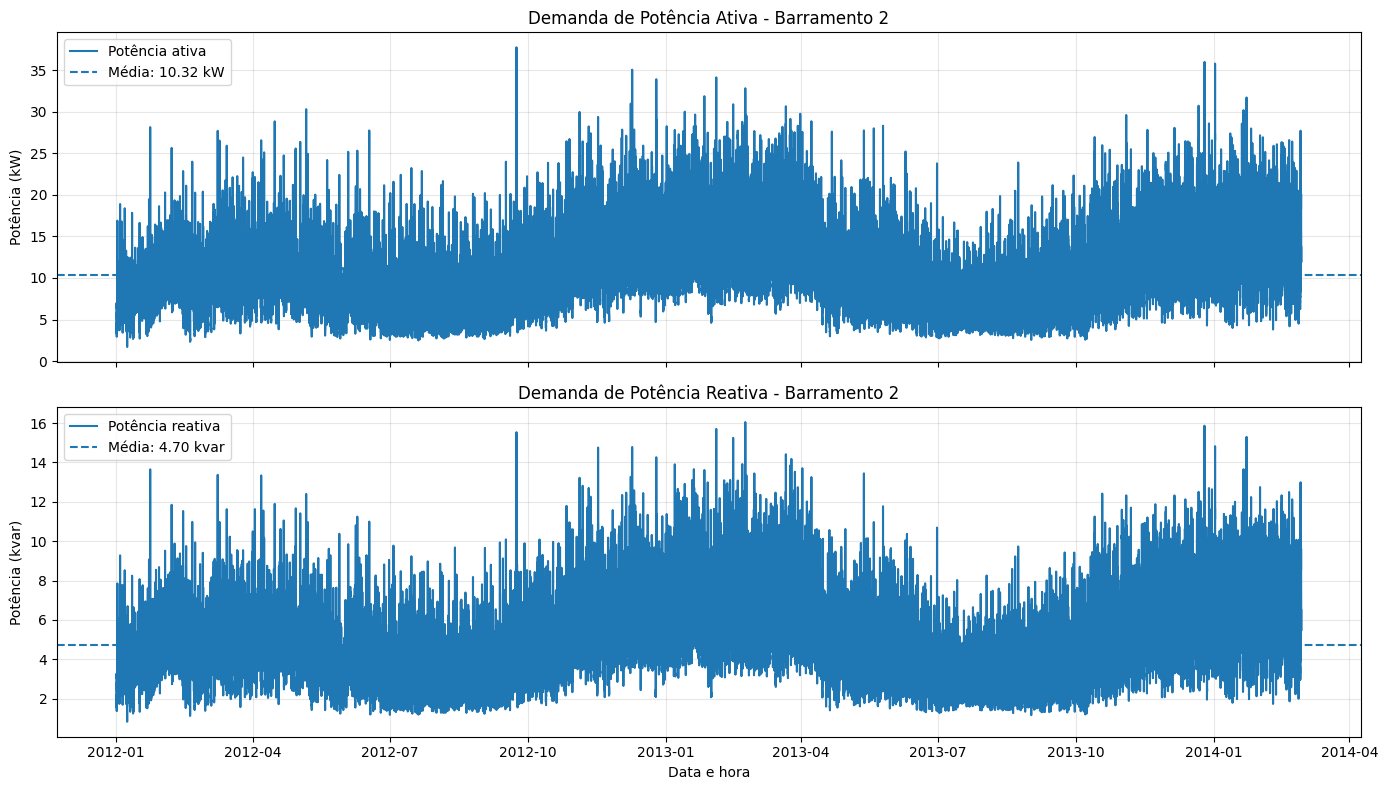

In [ ]:
plot_time_series(case=5, bus_number=2)

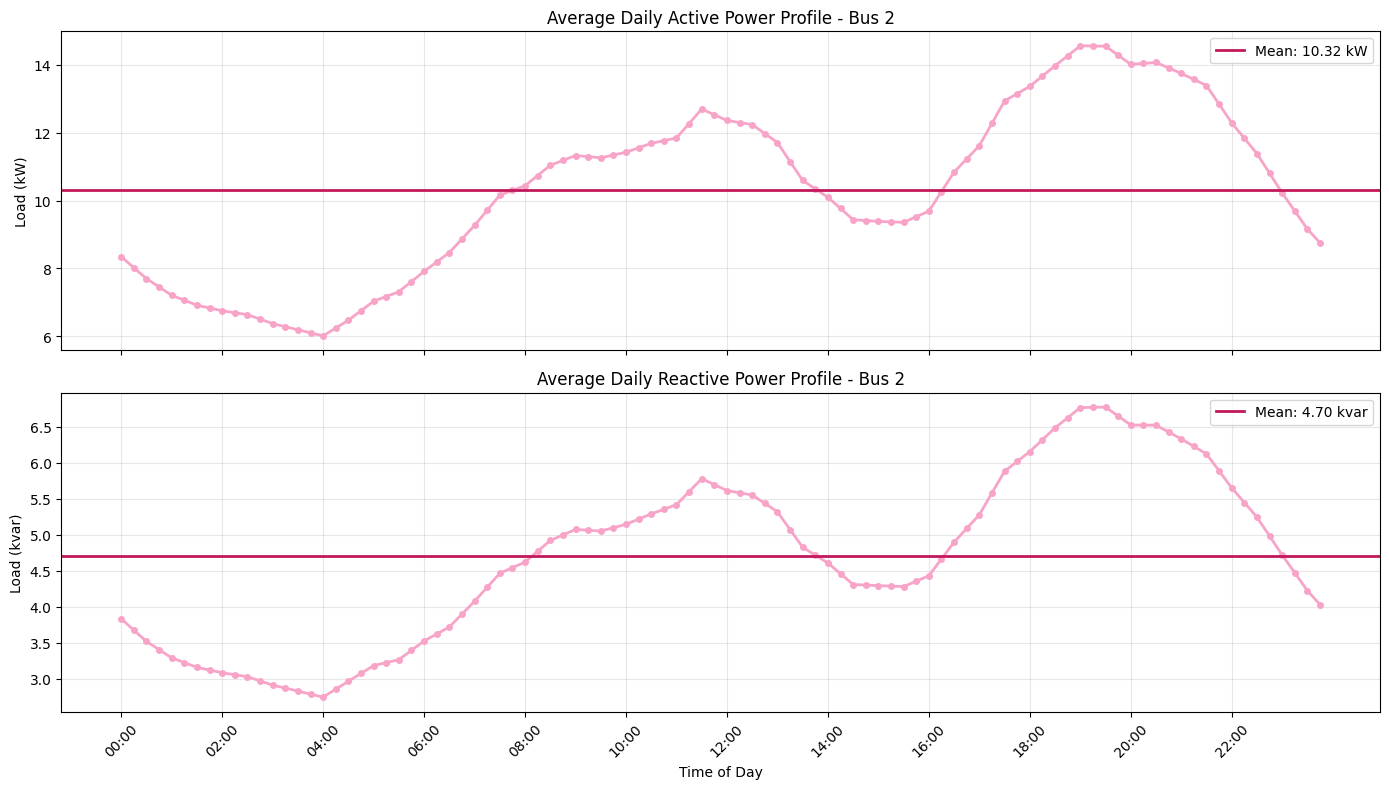

In [ ]:
plot_daily_average(case=5, bus_number=2)

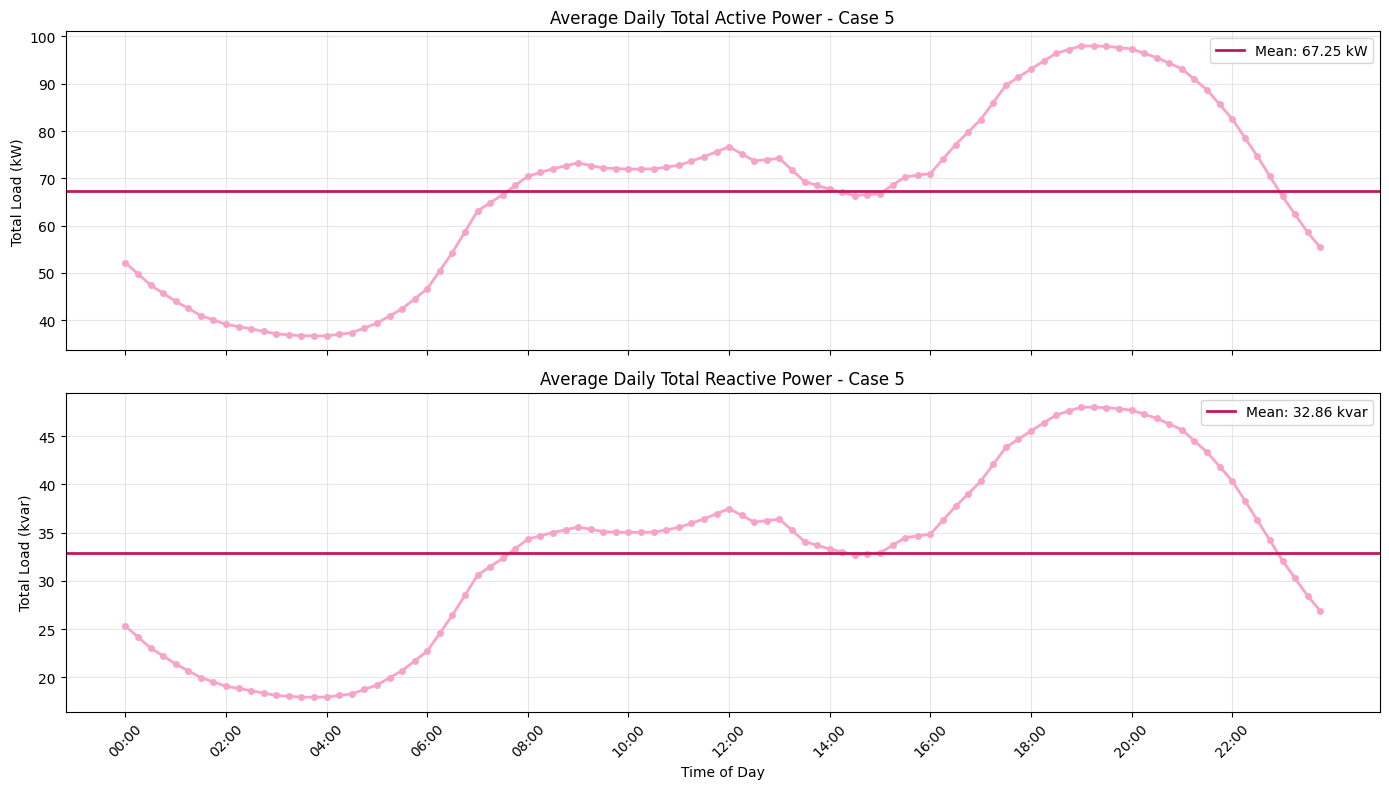

In [ ]:
plot_daily_average_total(case=5)

#### **Case 13**

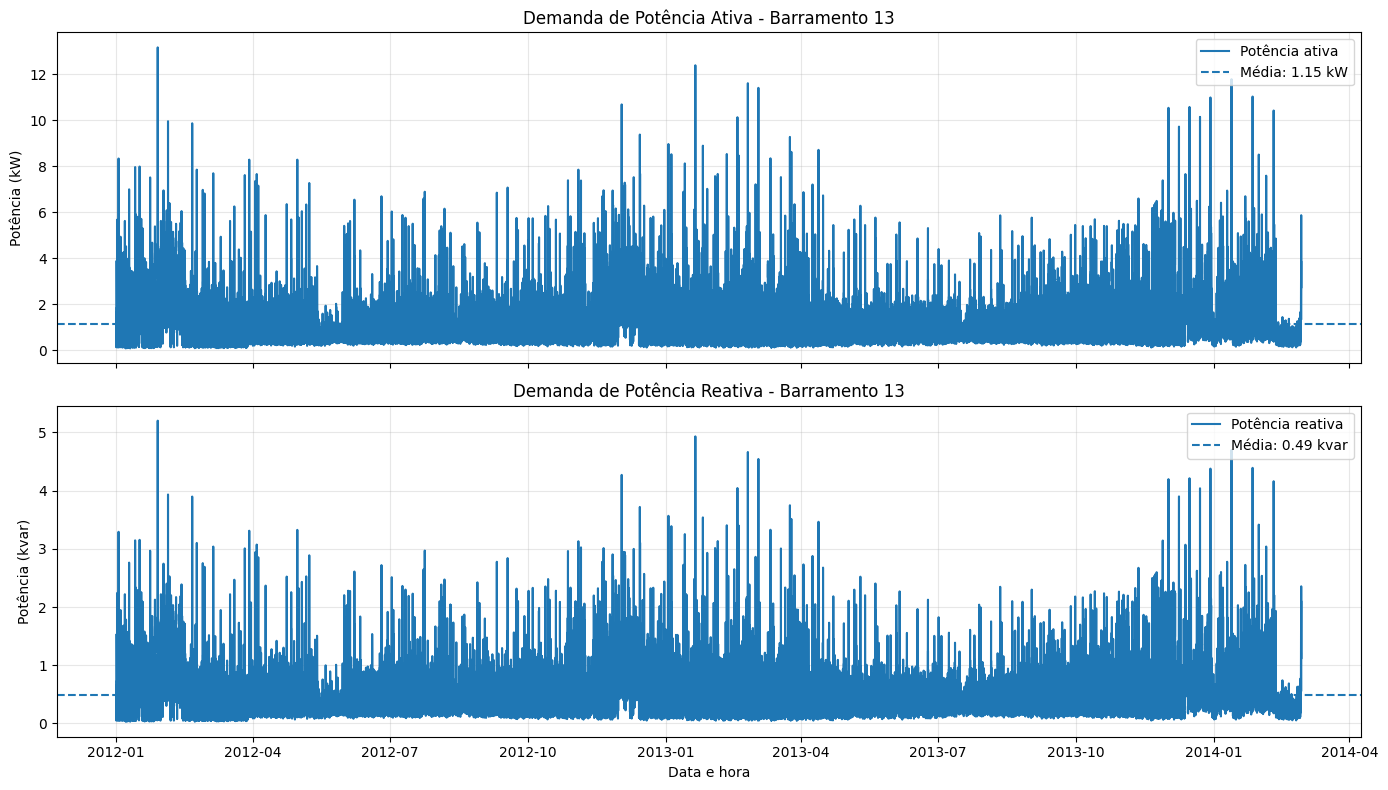

In [ ]:
plot_time_series(case=13, bus_number=13)

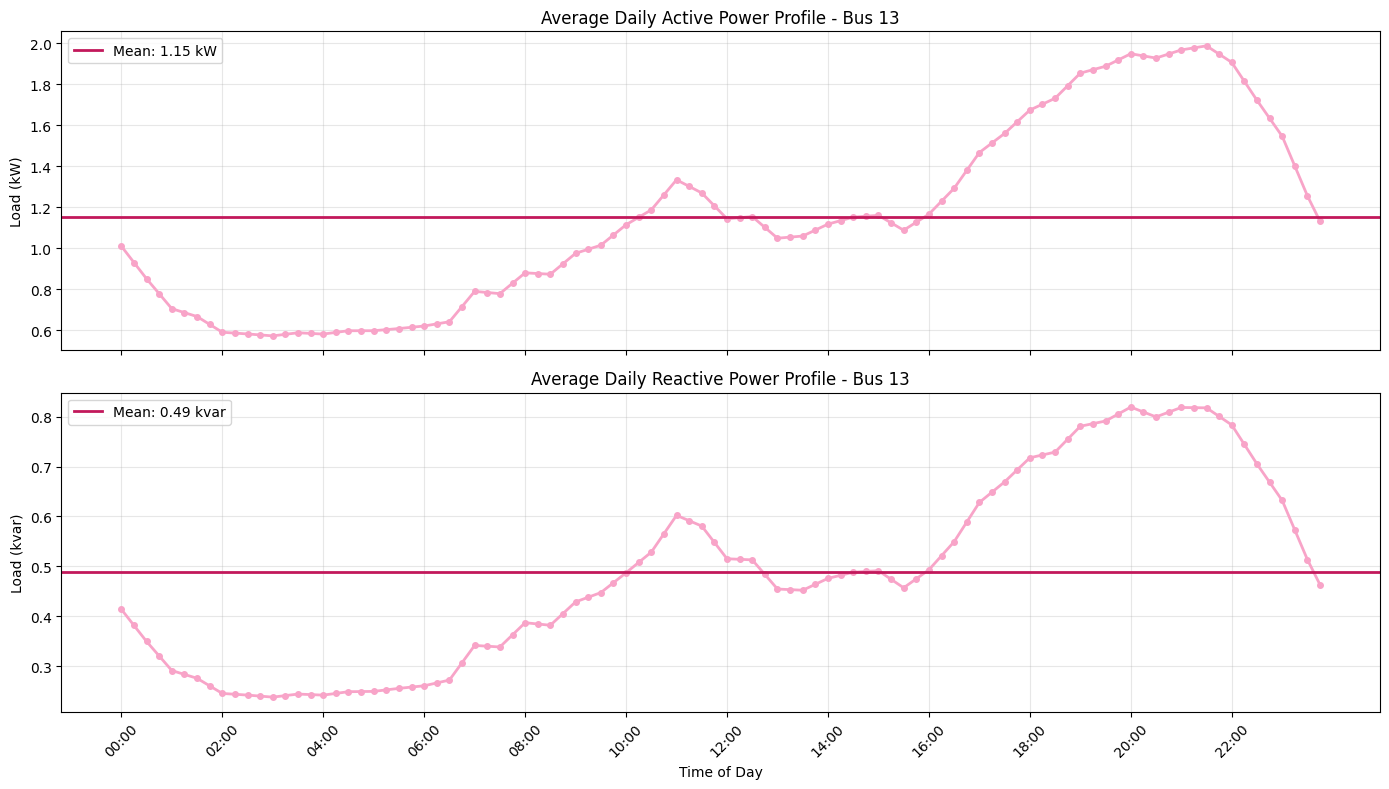

In [ ]:
plot_daily_average(case=13, bus_number=13)

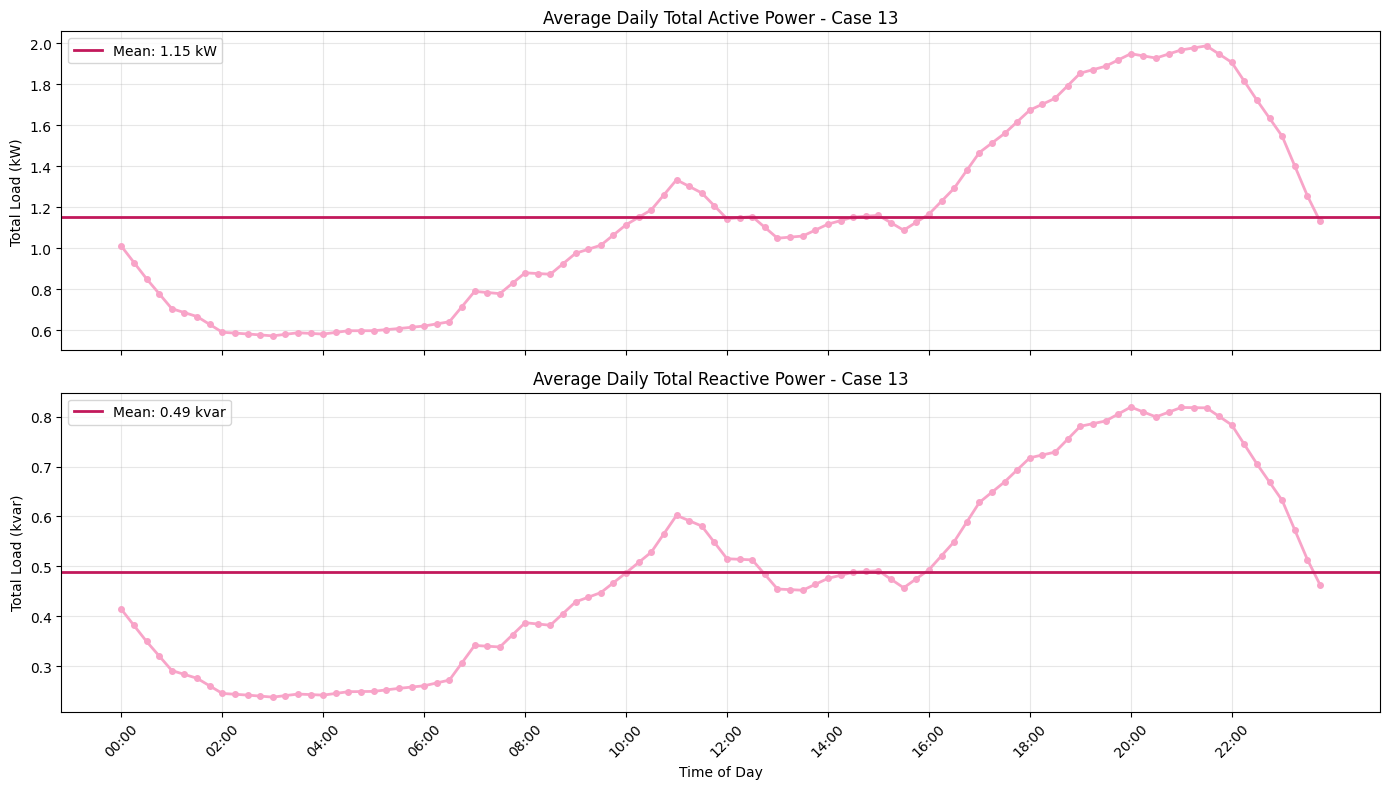

In [ ]:
plot_daily_average_total(case=13)

####**Case 34**

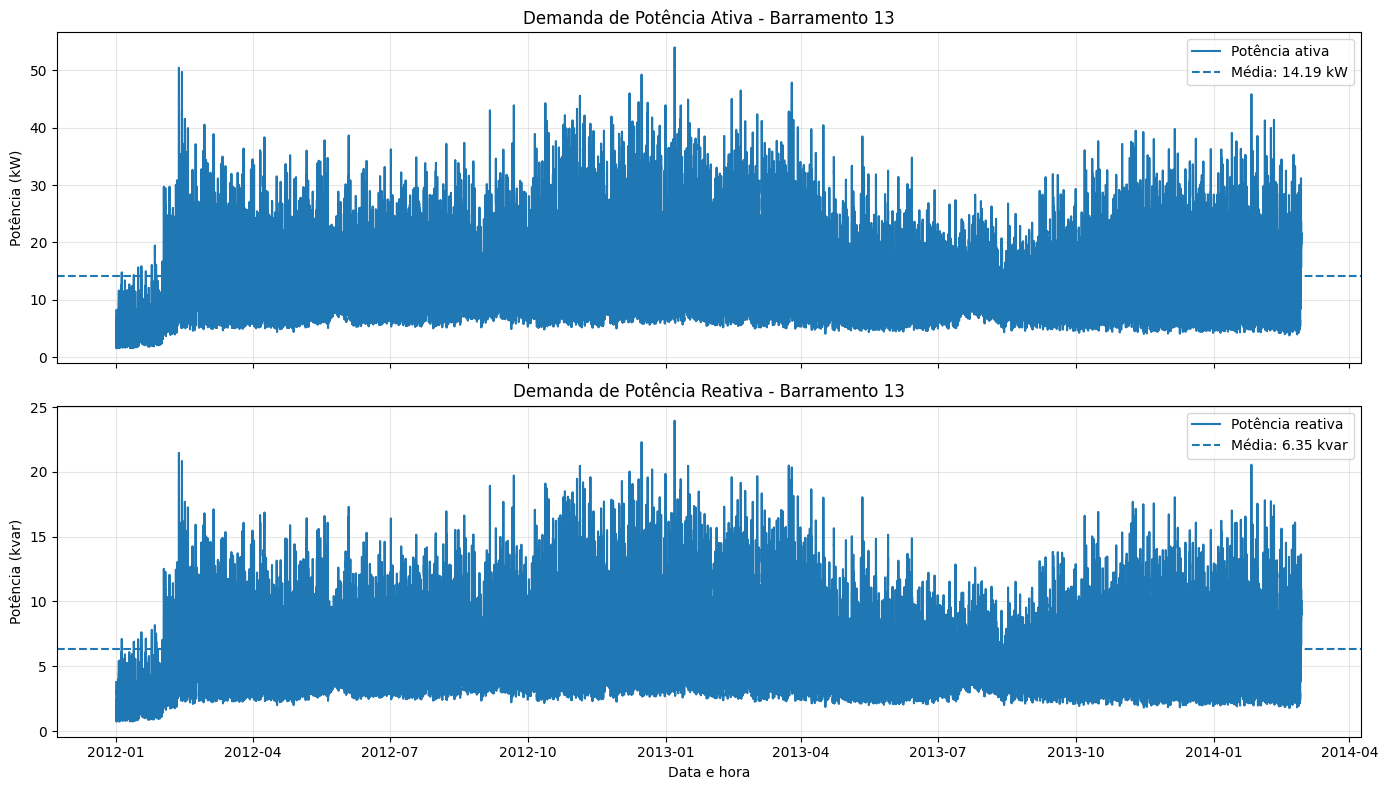

In [ ]:
plot_time_series(case=34, bus_number=13)

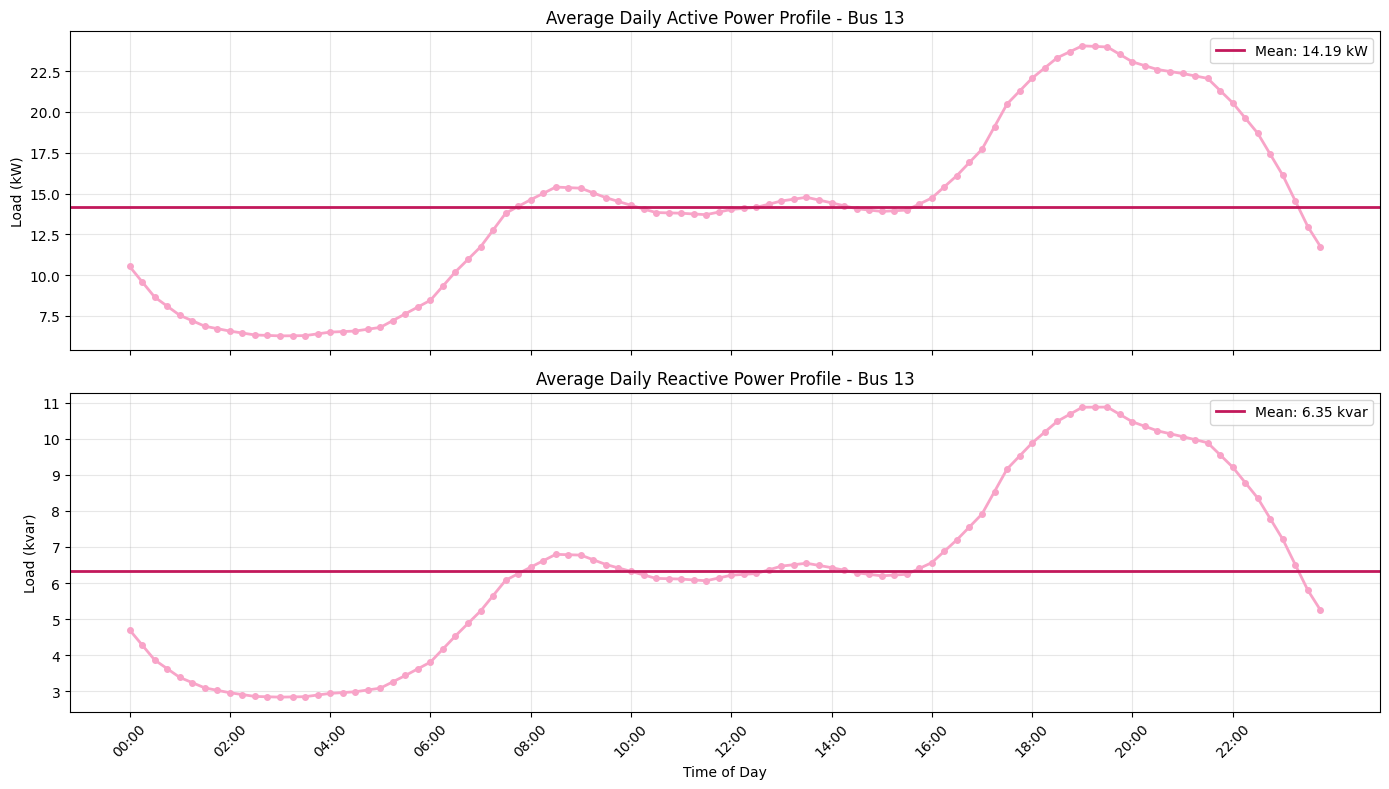

In [ ]:
plot_daily_average(case=34, bus_number=13)

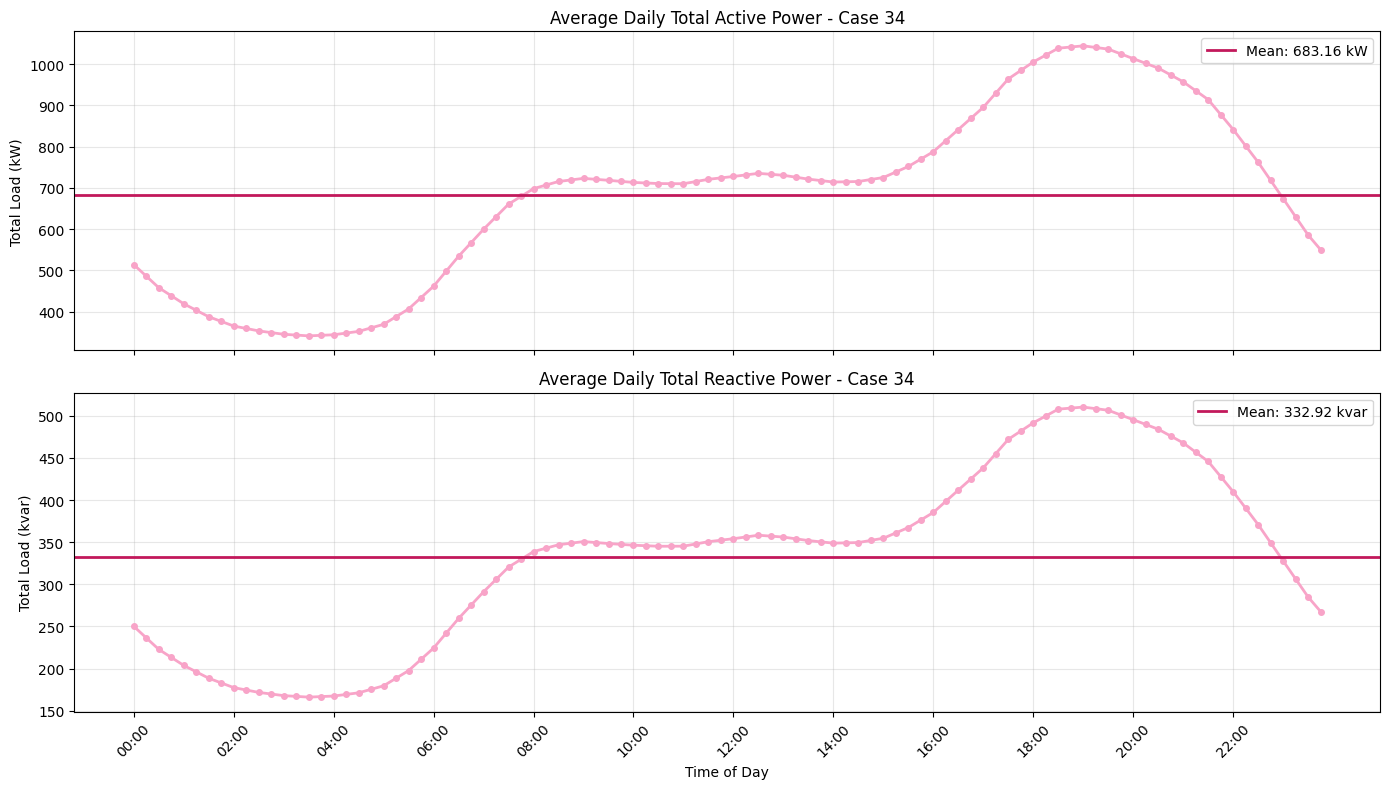

In [ ]:
plot_daily_average_total(case=34)